# 04 — RDKit exhaustive retrieval
Repeated in-memory, sequential requests on verified saved bits. See [methodology](../docs/exact_retrieval.md). Missing inputs stop without generation or fallback. Plots use an honest zero baseline; p95 is **p95 of per-query median latency**, not a confidence interval.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p/'src/chemtellect').is_dir()), None)
if ROOT is None:
    raise RuntimeError('Start JupyterLab within the repository.')
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10})
from chemtellect.exact_retrieval import run_benchmark, load_run

## Select inputs or inspect an existing run
Set `EXISTING_RUN_PATH` to a completed run to display it without modifying its files. Leave it `None` for a new run with metadata snapshots and saved PNG/SVG charts. Legacy fields display “not recorded”. Artifact and registered size are explicit; source/package/split derive from verified metadata.

In [2]:
artifact_path = ROOT/'data/processed/chemicalspace_new/package_00/fingerprints/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427'
INDEX_SIZE = 1000
EXISTING_RUN_PATH = None
# To inspect the original evidence without changing it:
# EXISTING_RUN_PATH = ROOT/'experiments/results/exact_retrieval/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/run_1494eeec3c0f489c9b67f7352dc573b7'

In [3]:
def present_exact(directory, saved):
    metadata, summary = saved['metadata'], saved['summary']
    timing = metadata['timing']
    title = f"{metadata['source']}/{metadata['package']} — {metadata['index_size']:,} index rows"
    provenance = {**{key: metadata['linkage'][key] for key in ('source', 'package', 'artifact_id', 'split_id')},
                  'queries': metadata['query_count'], 'index rows': metadata['index_size'],
                  'execution': timing.get('rdkit_execution', 'not recorded'),
                  'concurrent queries': timing['concurrent_queries'],
                  'warmup passes per k': timing['warmup_passes_per_k'],
                  'measured passes per k': timing['measured_passes_per_k'],
                  'timing-order seed': timing['timing_order_seed'],
                  'p95 definition': 'p95 of per-query median latency',
                  'percentile method': timing['percentile_method'],
                  'outside-timer overhead': timing.get('outside_timer_overhead', 'not recorded')}
    display(pd.Series(provenance, name='Value').rename_axis('Dataset / protocol').to_frame())
    rows = []
    for k, values in sorted(summary['by_k'].items(), key=lambda item: int(item[0])):
        s = values['across_query_medians_ns']
        rows.append({'k': int(k), 'Scoring median (µs)': s['scoring_ns']['median']/1000,
                     'Selection median (µs)': s['selection_ordering_ns']['median']/1000,
                     'Total median (µs)': s['retrieval_total_ns']['median']/1000,
                     'Total p95 of per-query median latency (µs)': s['retrieval_total_ns']['p95']/1000})
    table = pd.DataFrame(rows).set_index('k')
    display(table.round(3))
    display(pd.DataFrame([{'Preparation / output stage': name.replace('_', ' '),
                           'Elapsed (ms)': value/1e6}
                          for name, value in metadata['preparation_timings_ns'].items()]).round(3))
    memory = metadata.get('memory')
    snapshots = memory.get('snapshots', []) if isinstance(memory, dict) else []
    if snapshots:
        display(pd.DataFrame([{'Snapshot stage': s['stage'], 'UTC': s['sampled_utc'],
            'System total RAM (GiB)': s['system_ram_total_bytes']/2**30,
            'System available RAM (GiB)': s['system_ram_available_bytes']/2**30,
            'Process RSS (MiB)': s['process_rss_bytes']/2**20} for s in snapshots]).round(3))
    else:
        display(pd.DataFrame([{'Memory snapshots': 'not recorded'}]))
    fig, ax = plt.subplots(figsize=(8, 4.4), layout='constrained')
    ax.plot(table.index, table['Total median (µs)'], marker='o', label='Median of per-query medians')
    ax.plot(table.index, table.iloc[:, -1], marker='s', label='p95 of per-query median latency')
    ax.set(title=f'RDKit repeated in-memory retrieval\n{title}', xlabel='Independent top-k request',
           ylabel='Retrieval latency (µs)', xticks=table.index, ylim=(0, None))
    ax.set_ylim(0, max(table['Total median (µs)'].max(), table.iloc[:, -1].max()) * 1.15)
    ax.grid(alpha=.25); ax.legend(fontsize=9)
    names = []
    if directory is not None:
        for suffix in ('png', 'svg'):
            name = f'exact_latency.{suffix}'; fig.savefig(directory/name); names.append(name)
    display(fig); plt.close(fig)
    return names

## Execute and report
All execution is in the module. Scoring covers BulkTanimotoSimilarity; selection includes conversion, partition, exact ties and ordering. Preparation, evaluation, display and file writing are excluded from retrieval latency. Validation/evaluation overhead has no separate aggregate timing. Synchronous memory snapshots distinguish system RAM from process RSS; neither is true peak memory.

,Value
Dataset / protocol,
source,chemicalspace_new
package,package_00
artifact_id,628c36671feeb38e1a97a34dd664bb54f43851374fcea4...
split_id,f85552ea5b17e4829a09df82c79ad3bb2d762ee672c0f5...
queries,100
index rows,1000
execution,sequential; one query at a time
concurrent queries,1
warmup passes per k,1


,Scoring median (µs),Selection median (µs),Total median (µs),Total p95 of per-query median latency (µs)
k,,,,
10,90.896,36.911,128.352,131.166
25,90.986,37.221,128.368,130.891
50,90.342,38.186,128.727,131.967
100,90.246,40.851,131.257,135.430


,Preparation / output stage,Elapsed (ms)
0,selection metadata and split loading validation,3.948
1,full artifact loading integrity verification a...,8.710
2,selected nonzero validation,0.370
3,rdkit reconstruction,331.435
4,payload output writing,56.961
5,payload reload validation,99.003


,Snapshot stage,UTC,System total RAM (GiB),System available RAM (GiB),Process RSS (MiB)
0,before_input_loading,2026-11-10T20:06:33.603957+00:00,15.038,9.779,180.035
1,verified_packed_inputs,2026-11-10T20:06:33.617962+00:00,15.038,9.777,181.559
2,rdkit_prepared_before_retrieval,2026-11-10T20:06:33.949933+00:00,15.038,9.777,181.621
3,after_retrieval_and_outside_timer_validation,2026-11-10T20:06:34.351412+00:00,15.038,9.777,182.004


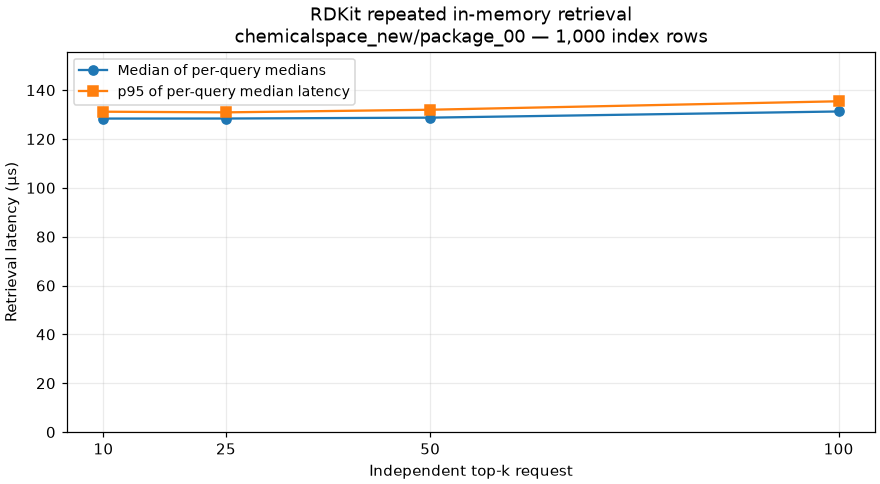

Verified run: experiments/results/exact_retrieval/chemicalspace_new/package_00/628c36671feeb38e1a97a34dd664bb54f43851374fcea4190a474479a12df427/run_0b54e3da1454423b88279253f6e32179


In [4]:
if EXISTING_RUN_PATH is None:
    run_path, metadata, summary = run_benchmark(
        ROOT, artifact_path, INDEX_SIZE, report_writer=present_exact)
else:
    run_path = EXISTING_RUN_PATH
    saved = load_run(run_path)
    present_exact(None, saved)
print('Verified run:', run_path.relative_to(ROOT))

Original query/index ordering and separate records with identical fingerprints are preserved. Saved float64 scores, exact ties and inclusive threshold membership remain authoritative. Results describe this dataset and 1K run; there is no 100M projection. FPSim2 comparisons use freshly paired RDKit timings in notebook 05, never this historical timing as their denominator.